In [29]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [30]:
df = pd.read_csv("superstoreOrders_cleaned.csv")

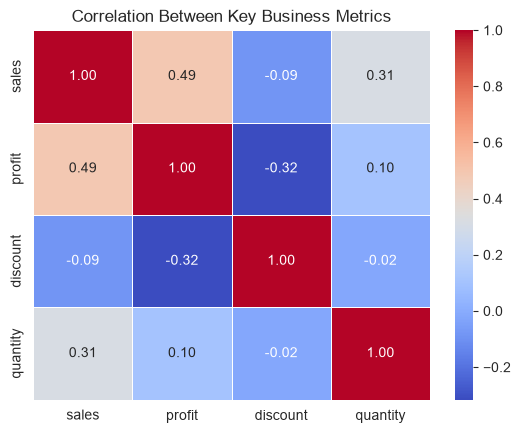

In [31]:

corr = df[['sales', 'profit', 'discount', 'quantity']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Between Key Business Metrics')

plt.show()

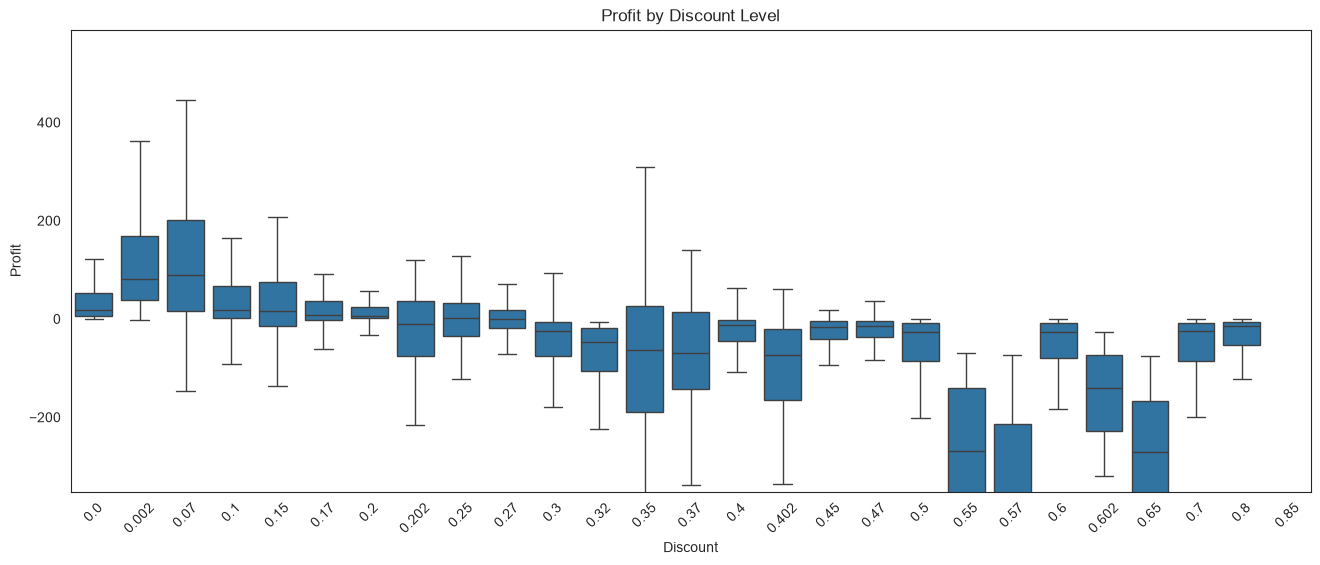

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))
sns.boxplot(data=df, x="discount", y="profit", showfliers=False)
plt.ylim(*df["profit"].quantile([0.01, 0.99]))
plt.title("Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.xticks(rotation=45)

plt.show()

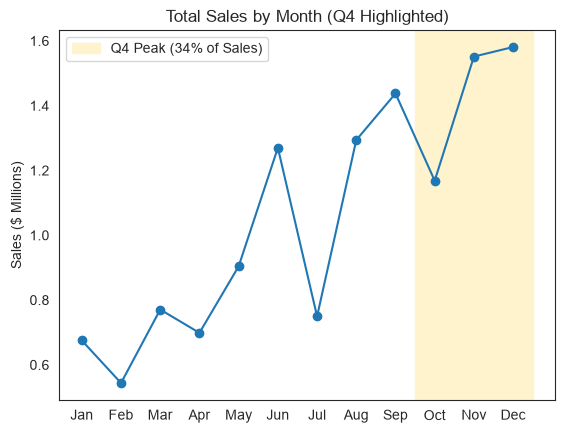

In [35]:
monthly = df.groupby("order_month")["sales"].sum() / 1e6
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.plot(months, monthly, marker="o")
plt.axvspan(8.5, 11.5, color="#fff3cd", label="Q4 Peak (34% of Sales)")
plt.title("Total Sales by Month (Q4 Highlighted)")
plt.ylabel("Sales ($ Millions)")
plt.legend()
plt.show()

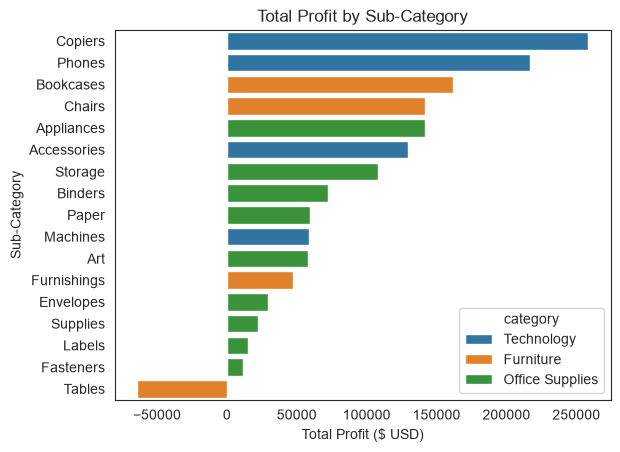

In [36]:
profit_df = df.groupby(["category", "sub_category"], as_index=False)["profit"].sum().sort_values("profit", ascending=False)
sns.barplot(data=profit_df, x="profit", y="sub_category", hue="category", dodge=False)
plt.title("Total Profit by Sub-Category")
plt.xlabel("Total Profit ($ USD)")
plt.ylabel("Sub-Category")
plt.show()

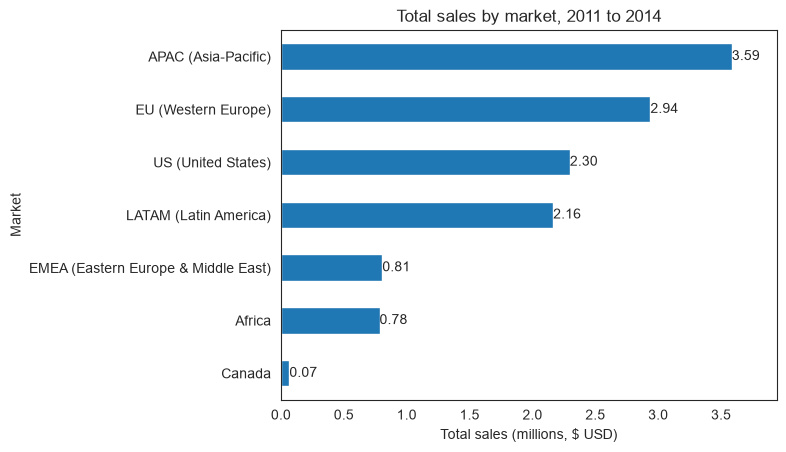

In [37]:
m = (df.groupby("market")["sales"].sum() / 1e6).sort_values()
ax = m.rename({"APAC": "APAC (Asia-Pacific)", "EU": "EU (Western Europe)", "US": "US (United States)", "LATAM": "LATAM (Latin America)", "EMEA": "EMEA (Eastern Europe & Middle East)"}).plot(kind="barh")
ax.bar_label(ax.containers[0], fmt="%.2f")
ax.set(title="Total sales by market, 2011 to 2014", xlabel="Total sales (millions, $ USD)", ylabel="Market", xmargin=0.1)
plt.show()

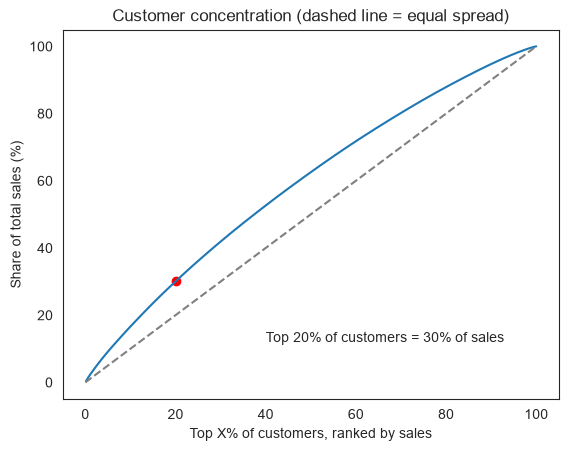

In [38]:
cs = df.groupby("customer_name")["sales"].sum().sort_values(ascending=False)
share = (cs.cumsum() / cs.sum() * 100).reset_index(drop=True)
x = (share.index + 1) / len(share) * 100
top = share[round(len(share) * 0.2) - 1]
plt.plot(x, share)
plt.plot([0, 100], [0, 100], "--", color="gray")
plt.scatter(20, top, color="red")
plt.text(40, 12, f"Top 20% of customers = {top:.0f}% of sales")
plt.title("Customer concentration (dashed line = equal spread)")
plt.xlabel("Top X% of customers, ranked by sales")
plt.ylabel("Share of total sales (%)")
plt.show()


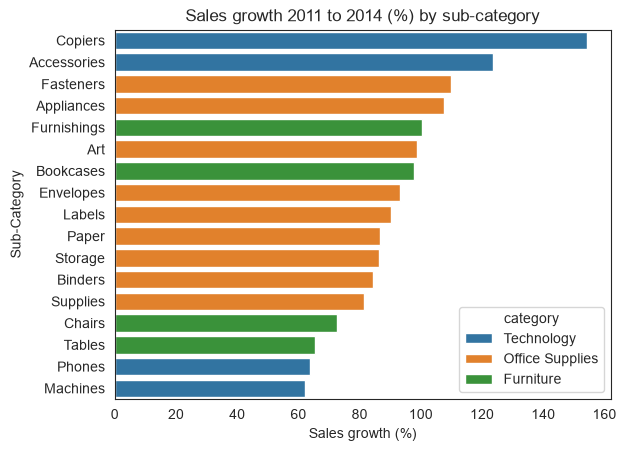

In [39]:
p = df.pivot_table(index=["category", "sub_category"], columns="year", values="sales", aggfunc="sum")
growth = ((p[2014] / p[2011] - 1) * 100).reset_index(name="growth").sort_values("growth", ascending=False)
sns.barplot(data=growth, x="growth", y="sub_category", hue="category", dodge=False)
plt.title("Sales growth 2011 to 2014 (%) by sub-category")
plt.xlabel("Sales growth (%)")
plt.ylabel("Sub-Category")
plt.show()

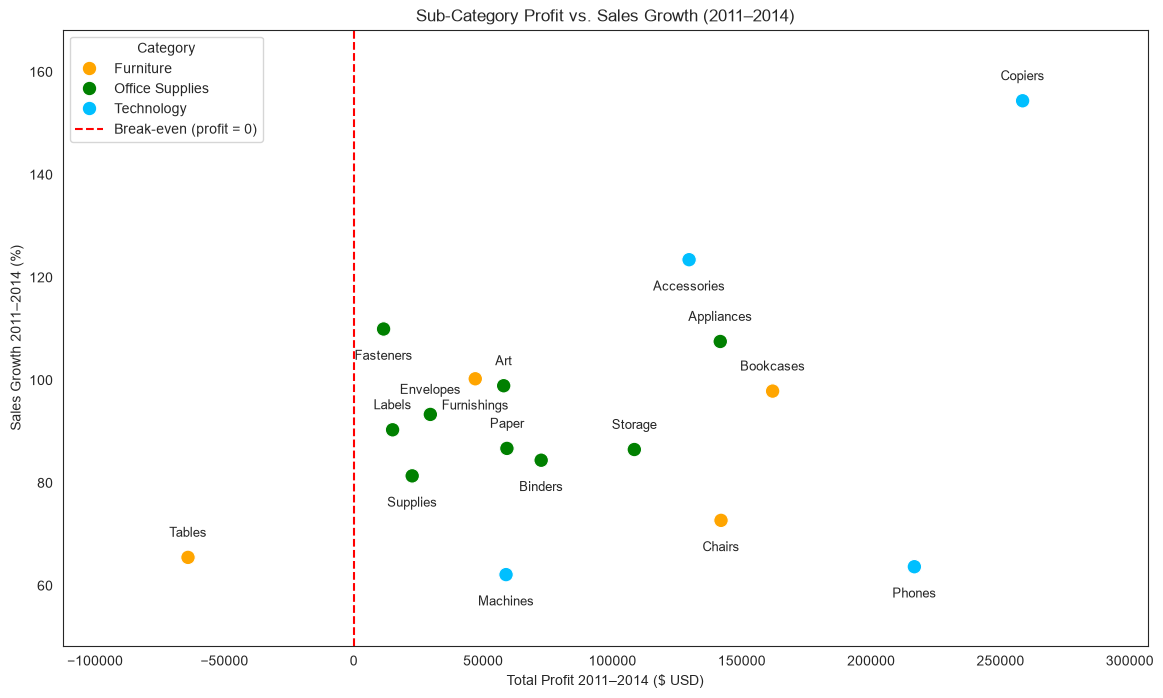

In [40]:
p = df.pivot_table(index=["category", "sub_category"], columns="year", values="sales", aggfunc="sum")
combo = df.groupby(["category", "sub_category"], as_index=False)["profit"].sum()
combo["growth"] = ((p[2014] / p[2011] - 1) * 100).values

sns.set_style("white")
plt.figure(figsize=(14, 8))
plt.title("Sub-Category Profit vs. Sales Growth (2011–2014)")
plt.xlabel("Total Profit 2011–2014 ($ USD)")
plt.ylabel("Sales Growth 2011–2014 (%)")
sns.scatterplot(data=combo, x="profit", y="growth", hue="category", palette={"Technology": "deepskyblue", "Furniture": "orange", "Office Supplies": "green"}, s=110)
plt.axvline(0, color="red", linestyle="--", label="Break-even (profit = 0)")
for i, r in combo.sort_values("profit").reset_index(drop=True).iterrows(): plt.text(r.profit, r.growth + (4 if i % 2 == 0 else -6), r.sub_category, fontsize=9, ha="center")
plt.margins(0.15)
plt.legend(title="Category")
plt.show()